       VISIONPORT - COCO TRAFFIC DATASET EXPLORATION

PLEASE UPLOAD YOUR COCO128 ZIP FILE


Saving COCO128_TRAFFIC_SAMPLE.zip to COCO128_TRAFFIC_SAMPLE.zip

Uploaded Dataset: COCO128_TRAFFIC_SAMPLE.zip

Dataset extracted successfully!

SEARCHING FOR DATASET FILES...

DATASET INFORMATION
Total Photographs: 3
Total Annotation Files: 3

Total COCO Categories: 80

TRAFFIC DATASET FILTERING COMPLETED
Traffic Images Found: 3
Images Without Matching Labels: 0

REAL TRAFFIC PHOTOGRAPHS WITH BOUNDING BOXES


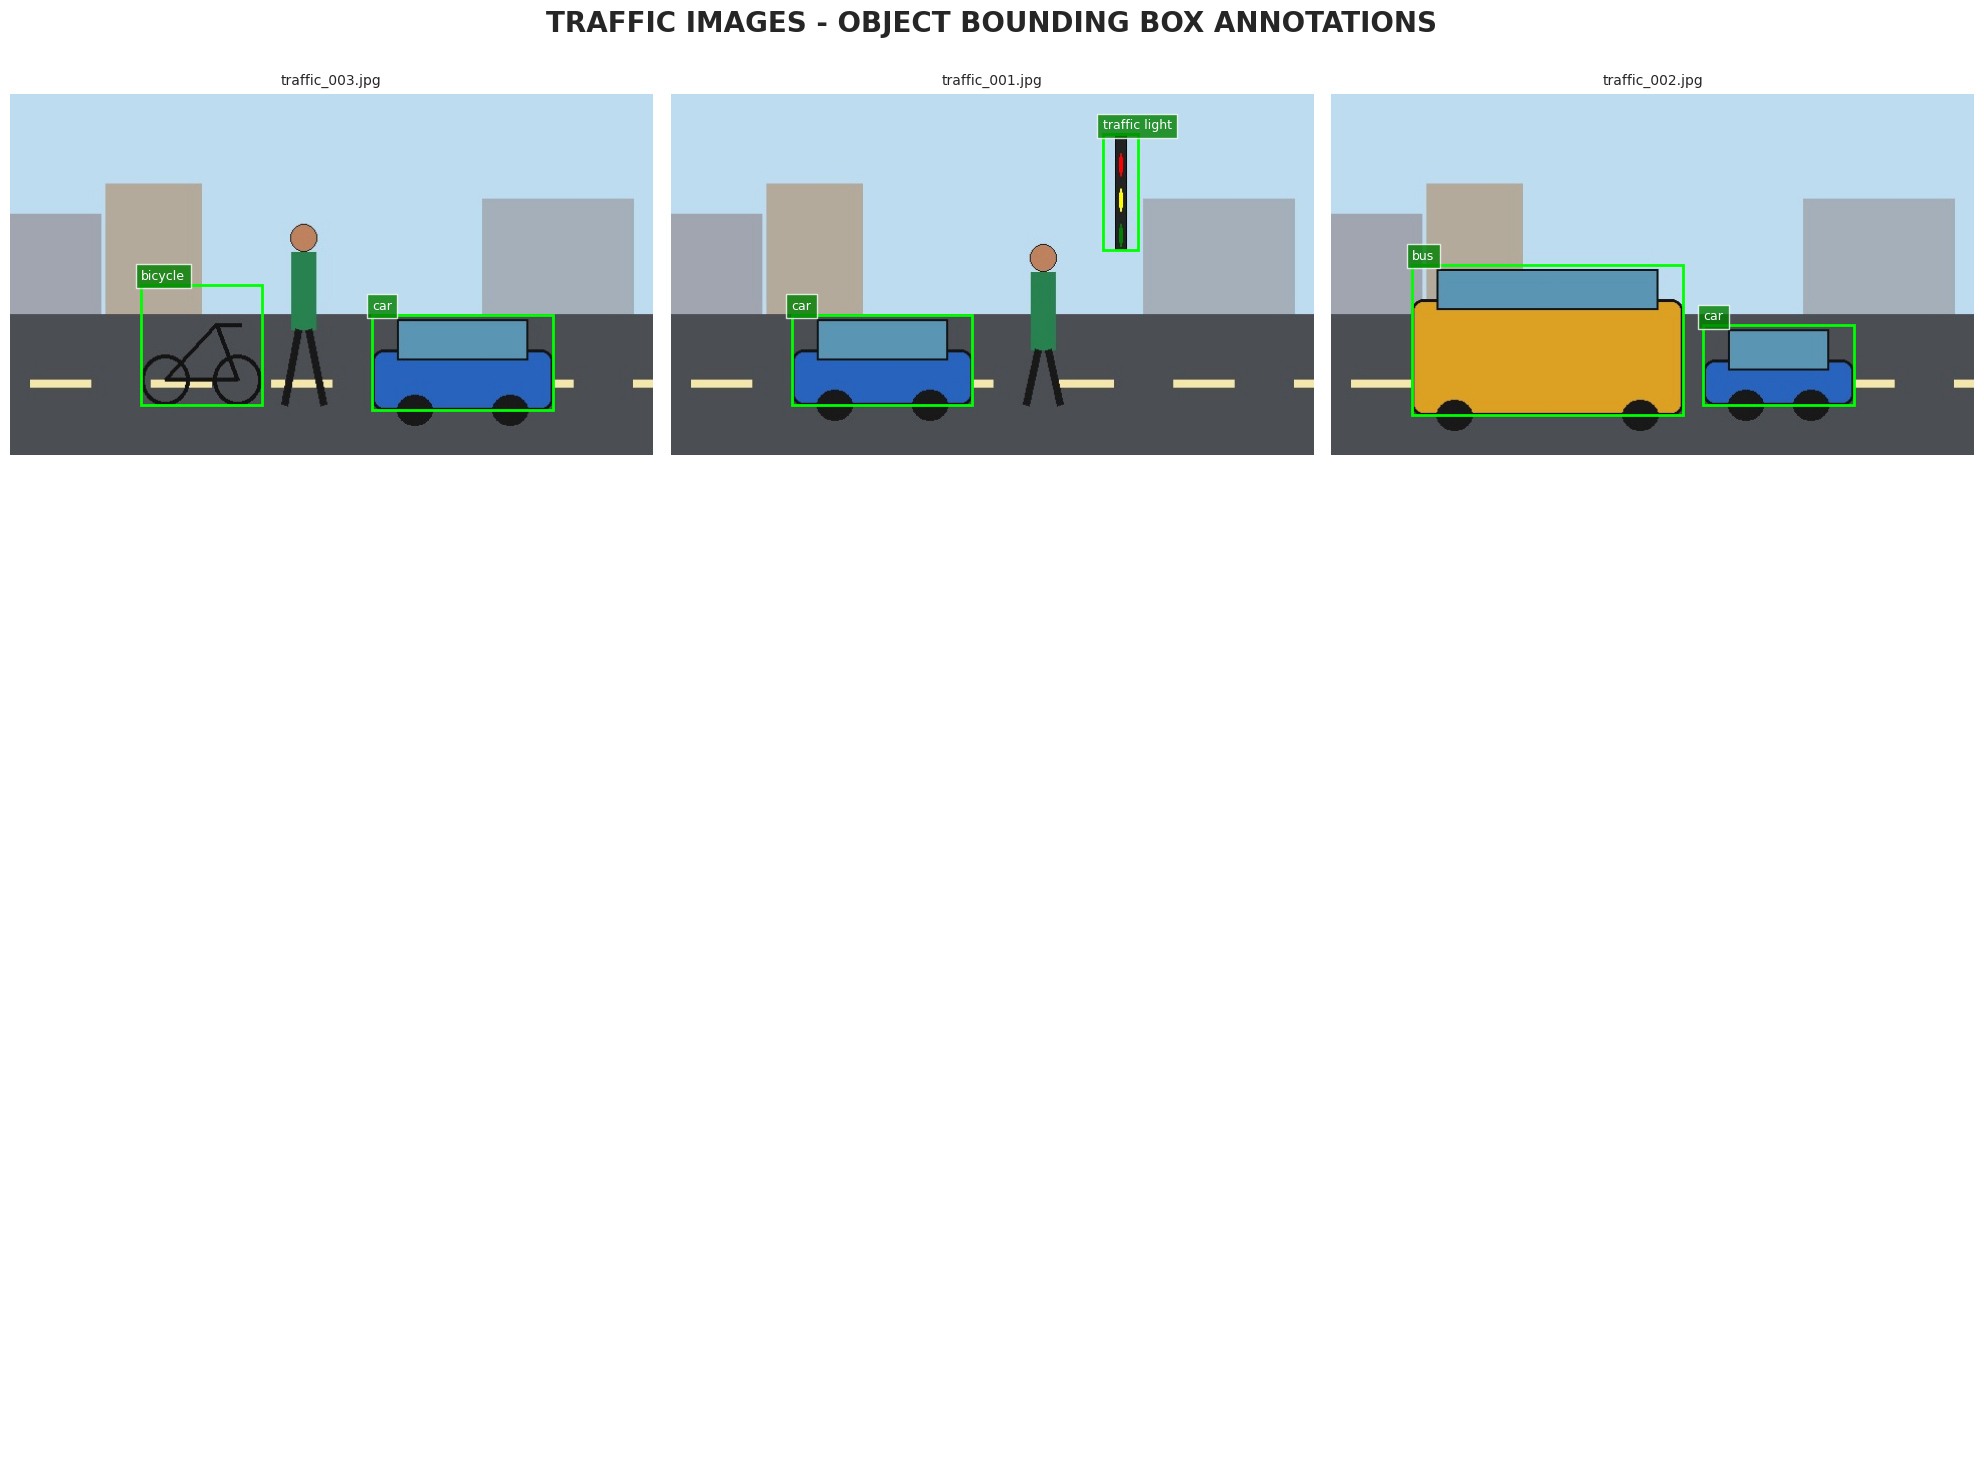


TRAFFIC CATEGORY DISTRIBUTION


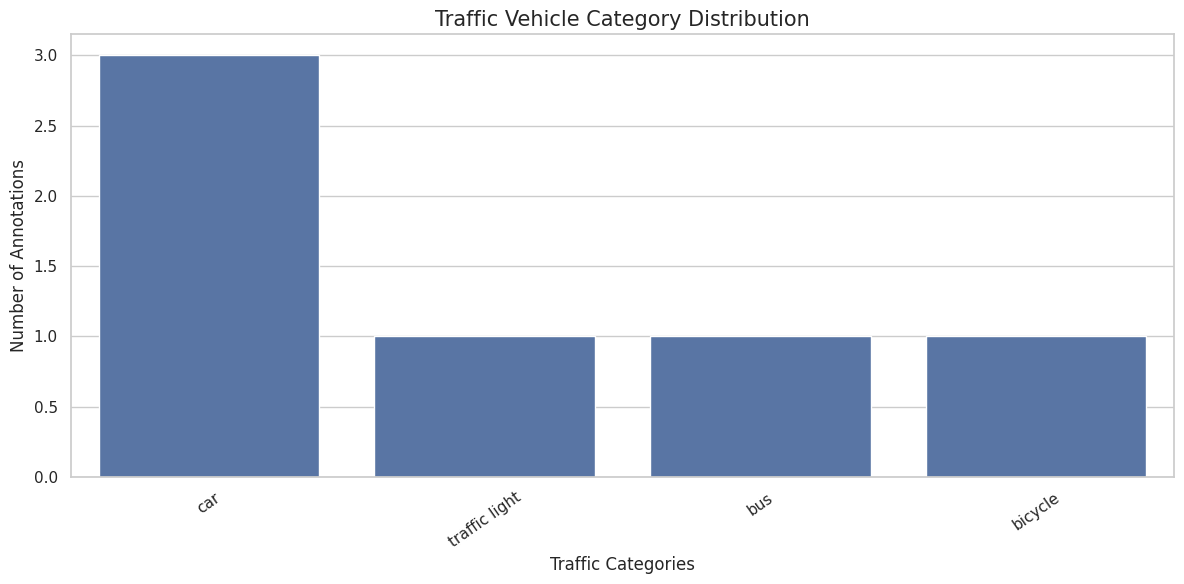


TRAFFIC CATEGORY PERCENTAGE DISTRIBUTION


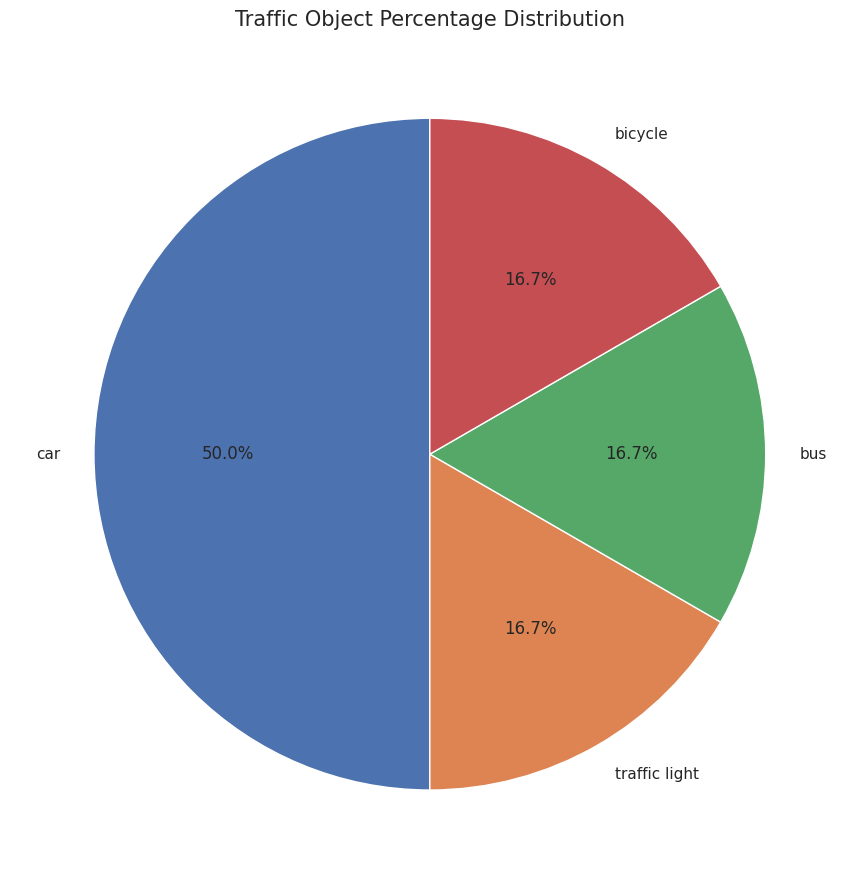


BOUNDING BOX DIMENSION ANALYSIS


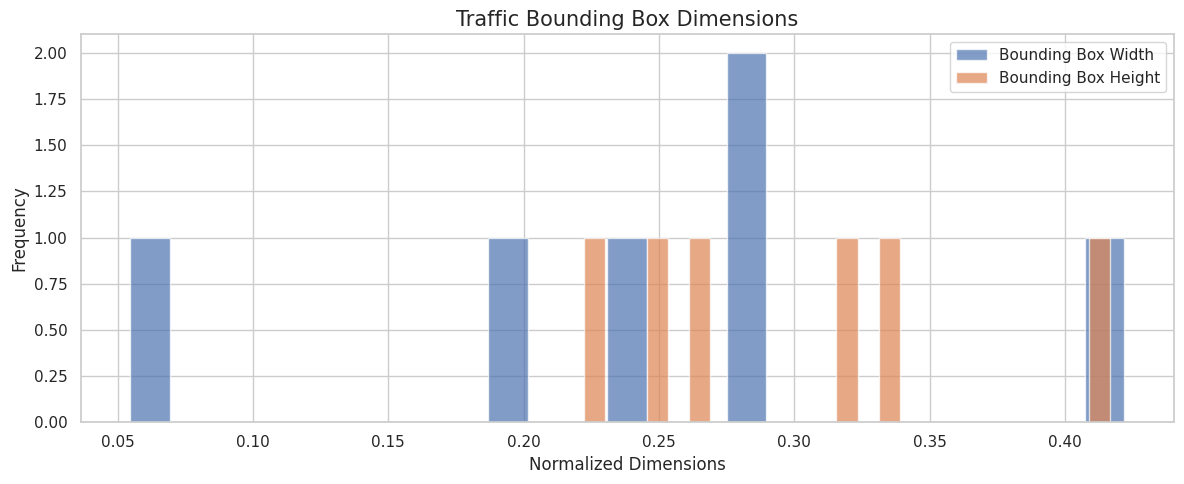


OBJECTS PER IMAGE ANALYSIS


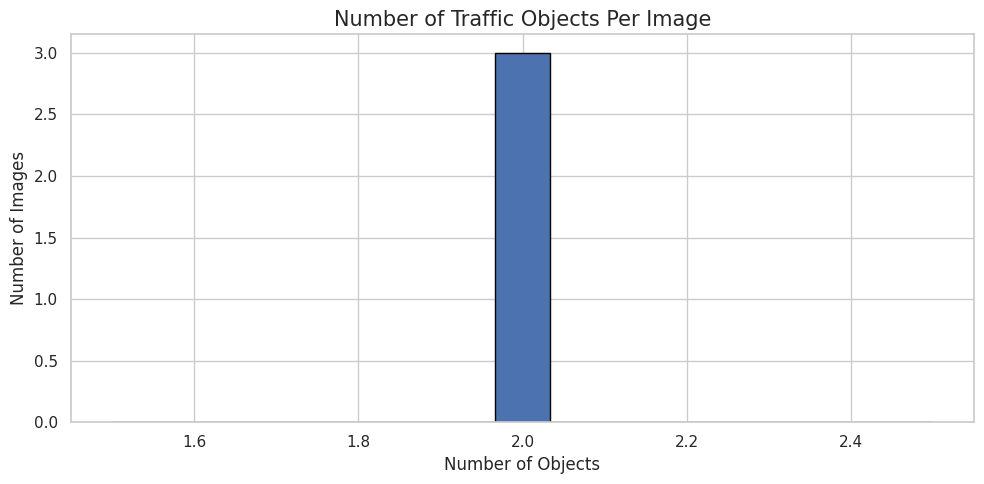


ANNOTATION TABLE


,Image,Category,X Center,Y Center,Width,Height
0,traffic_001.jpg,car,0.3281,0.7361,0.2812,0.2500
1,traffic_001.jpg,traffic light,0.6992,0.2708,0.0547,0.3194
2,traffic_002.jpg,bus,0.3359,0.6806,0.4219,0.4167
3,traffic_002.jpg,car,0.6953,0.7500,0.2344,0.2222
4,traffic_003.jpg,bicycle,0.2969,0.6944,0.1875,0.3333
5,traffic_003.jpg,car,0.7031,0.7431,0.2812,0.2639



Total Annotation Records: 6

CATEGORY SUMMARY TABLE


,Traffic Category,Annotation Count
0,car,3
1,traffic light,1
2,bus,1
3,bicycle,1



       FINAL TRAFFIC DATASET REPORT
Total Dataset Images : 3
Total Annotation Files: 3
Traffic Images       : 3
Traffic Categories   : 4
Total Annotations    : 6

CATEGORY COUNTS
car : 3
traffic light : 1
bus : 1
bicycle : 1

Average Objects Per Image: 2.0
Average Box Width: 0.2435
Average Box Height: 0.3009

SAVING ANALYSIS RESULTS
Annotation CSV saved.
Category summary CSV saved.
Dataset report saved.

       SKILL-5 EXPERIMENT COMPLETED SUCCESSFULLY!

COMPLETED TASKS:
1. COCO128 dataset uploaded.
2. Dataset extracted successfully.
3. Images and annotations identified.
4. Traffic categories selected.
5. Traffic photographs displayed.
6. Bounding boxes visualized.
7. Category distribution analyzed.
8. Category percentage chart generated.
9. Bounding-box dimensions analyzed.
10. Objects per image analyzed.
11. Annotation table generated.
12. Dataset report created.
13. Analysis results saved.

OUTPUT DIRECTORY:
/content/traffic_analysis_results

ALL SKILL-5 TASKS COMPLETED!


In [1]:
# ================================================================
# VISIONPORT - DEEP LEARNING SKILL LAB
# SKILL-5
#
# COCO DATASET EXPLORATION:
# INDIAN TRAFFIC IMAGES, CATEGORIES AND
# BOUNDING-BOX ANNOTATIONS
#
# Platform: Google Colab
# Dataset: COCO128
# ================================================================


# ================================================================
# 1. INSTALL AND IMPORT REQUIRED LIBRARIES
# ================================================================

!pip install -q numpy pandas matplotlib seaborn pillow

import os
import glob
import zipfile
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns

from PIL import Image
from collections import Counter
from google.colab import files
from IPython.display import display

# Set visualization style.
sns.set_theme(style="whitegrid")

# Set random seed for reproducible sampling.
random.seed(42)
np.random.seed(42)

print("=" * 70)
print("       VISIONPORT - COCO TRAFFIC DATASET EXPLORATION")
print("=" * 70)


# ================================================================
# 2. UPLOAD COCO128 DATASET ZIP FILE
# ================================================================

print("\nPLEASE UPLOAD YOUR COCO128 ZIP FILE")

# Open the Google Colab upload window.
uploaded = files.upload()

# Identify the uploaded ZIP file.
zip_file = next(
    (
        filename
        for filename in uploaded
        if filename.lower().endswith(".zip")
    ),
    None
)

# Stop execution if no ZIP file was uploaded.
if zip_file is None:
    raise ValueError(
        "No ZIP file found. Please upload the COCO128 ZIP dataset."
    )

print("\nUploaded Dataset:", zip_file)


# ================================================================
# 3. EXTRACT THE DATASET
# ================================================================

# Define the dataset extraction directory.
dataset_path = "/content/traffic_coco"

# Create the directory if it does not exist.
os.makedirs(dataset_path, exist_ok=True)

# Extract the ZIP archive.
with zipfile.ZipFile(zip_file, "r") as archive:

    # Extract all dataset files.
    archive.extractall(dataset_path)

print("\nDataset extracted successfully!")


# ================================================================
# 4. FIND IMAGE AND ANNOTATION FILES
# ================================================================

print("\nSEARCHING FOR DATASET FILES...")

# Supported image extensions.
image_extensions = [
    "*.jpg",
    "*.jpeg",
    "*.png"
]

# Find all images recursively.
image_files = []

for extension in image_extensions:

    image_files.extend(
        glob.glob(
            os.path.join(
                dataset_path,
                "**",
                extension
            ),
            recursive=True
        )
    )

# Find YOLO annotation text files.
label_files = glob.glob(
    os.path.join(
        dataset_path,
        "**",
        "labels",
        "**",
        "*.txt"
    ),
    recursive=True
)

# Remove duplicate paths and sort.
image_files = sorted(set(image_files))
label_files = sorted(set(label_files))

# Validate dataset files.
if not image_files:

    raise FileNotFoundError(
        "No images found. Please check the uploaded ZIP file."
    )

if not label_files:

    raise FileNotFoundError(
        "No YOLO annotation files found. "
        "Please upload a dataset containing labels."
    )

# Create annotation lookup using image filenames.
label_lookup = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in label_files
}

print("\nDATASET INFORMATION")

print("Total Photographs:", len(image_files))
print("Total Annotation Files:", len(label_files))


# ================================================================
# 5. DEFINE COCO CATEGORY NAMES
# ================================================================

# COCO 80-class category mapping used by YOLO-format labels.
class_names = [
    "person",
    "bicycle",
    "car",
    "motorcycle",
    "airplane",
    "bus",
    "train",
    "truck",
    "boat",
    "traffic light",
    "fire hydrant",
    "stop sign",
    "parking meter",
    "bench",
    "bird",
    "cat",
    "dog",
    "horse",
    "sheep",
    "cow",
    "elephant",
    "bear",
    "zebra",
    "giraffe",
    "backpack",
    "umbrella",
    "handbag",
    "tie",
    "suitcase",
    "frisbee",
    "skis",
    "snowboard",
    "sports ball",
    "kite",
    "baseball bat",
    "baseball glove",
    "skateboard",
    "surfboard",
    "tennis racket",
    "bottle",
    "wine glass",
    "cup",
    "fork",
    "knife",
    "spoon",
    "bowl",
    "banana",
    "apple",
    "sandwich",
    "orange",
    "broccoli",
    "carrot",
    "hot dog",
    "pizza",
    "donut",
    "cake",
    "chair",
    "couch",
    "potted plant",
    "bed",
    "dining table",
    "toilet",
    "tv",
    "laptop",
    "mouse",
    "remote",
    "keyboard",
    "cell phone",
    "microwave",
    "oven",
    "toaster",
    "sink",
    "refrigerator",
    "book",
    "clock",
    "vase",
    "scissors",
    "teddy bear",
    "hair drier",
    "toothbrush"
]

print("\nTotal COCO Categories:", len(class_names))


# ================================================================
# 6. SELECT TRAFFIC-RELATED CATEGORIES
# ================================================================

# Main vehicle categories.
vehicle_ids = [
    1,   # Bicycle
    2,   # Car
    3,   # Motorcycle
    5,   # Bus
    7    # Truck
]

# Additional road-related categories.
road_ids = [
    9,    # Traffic light
    11,   # Stop sign
    12    # Parking meter
]

# Combine selected categories.
selected_ids = vehicle_ids + road_ids

# Store traffic image information.
traffic_records = []

# Count occurrences of each traffic category.
category_counts = Counter()

# Count images without matching annotations.
missing_annotations = 0

# Process every image.
for image_path in image_files:

    # Extract image filename without extension.
    image_name = os.path.splitext(
        os.path.basename(image_path)
    )[0]

    # Find corresponding annotation file.
    label_path = label_lookup.get(image_name)

    if label_path is None:

        missing_annotations += 1
        continue

    objects = []

    # Read YOLO annotation file.
    with open(label_path, "r") as file:

        lines = file.readlines()

    # Process each annotation.
    for line in lines:

        values = line.strip().split()

        # YOLO format requires at least 5 values:
        # class_id, x_center, y_center, width, height.
        if len(values) < 5:
            continue

        try:

            cid = int(float(values[0]))

            xc, yc, w, h = map(
                float,
                values[1:5]
            )

        except ValueError:

            continue

        # Ignore categories that are not traffic-related.
        if cid not in selected_ids:
            continue

        # Validate normalized bounding-box coordinates.
        if not (
            0 <= xc <= 1
            and 0 <= yc <= 1
            and 0 < w <= 1
            and 0 < h <= 1
        ):
            continue

        # Store object annotation.
        obj = {
            "id": cid,
            "name": class_names[cid],
            "xc": xc,
            "yc": yc,
            "w": w,
            "h": h
        }

        objects.append(obj)

    # Keep only images containing at least one vehicle.
    has_vehicle = any(
        obj["id"] in vehicle_ids
        for obj in objects
    )

    if has_vehicle:

        # Store image and its annotations.
        traffic_records.append({
            "path": image_path,
            "objects": objects
        })

        # Update category counts.
        for obj in objects:

            category_counts[obj["name"]] += 1


print("\nTRAFFIC DATASET FILTERING COMPLETED")

print(
    "Traffic Images Found:",
    len(traffic_records)
)

print(
    "Images Without Matching Labels:",
    missing_annotations
)

if not traffic_records:

    raise ValueError(
        "No vehicle images were found. "
        "Please verify the dataset and annotation format."
    )


# ================================================================
# 7. DISPLAY REAL TRAFFIC IMAGES WITH BOUNDING BOXES
# ================================================================

print("\nREAL TRAFFIC PHOTOGRAPHS WITH BOUNDING BOXES")

# Randomly select up to 9 traffic images.
sample = random.sample(
    traffic_records,
    min(9, len(traffic_records))
)

# Create a 3x3 image visualization grid.
fig, axes = plt.subplots(
    3,
    3,
    figsize=(20, 15)
)

axes = axes.flatten()

# Display each selected image.
for ax, record in zip(axes, sample):

    # Open the traffic photograph.
    img = Image.open(
        record["path"]
    ).convert("RGB")

    # Obtain original image dimensions.
    width, height = img.size

    # Display the photograph.
    ax.imshow(img)

    # Draw all object bounding boxes.
    for obj in record["objects"]:

        # Convert normalized coordinates into pixels.
        xc = obj["xc"] * width
        yc = obj["yc"] * height

        bw = obj["w"] * width
        bh = obj["h"] * height

        # Calculate top-left corner.
        x = xc - bw / 2
        y = yc - bh / 2

        # Create rectangular bounding box.
        rectangle = patches.Rectangle(
            (x, y),
            bw,
            bh,
            linewidth=2,
            edgecolor="lime",
            facecolor="none"
        )

        ax.add_patch(rectangle)

        # Add category label.
        ax.text(
            x,
            max(0, y - 5),
            obj["name"],
            color="white",
            fontsize=9,
            bbox={
                "facecolor": "green",
                "alpha": 0.8
            }
        )

    # Display image filename.
    ax.set_title(
        os.path.basename(record["path"]),
        fontsize=10
    )

    ax.axis("off")


# Hide unused subplots.
for ax in axes[len(sample):]:

    ax.axis("off")


plt.suptitle(
    "TRAFFIC IMAGES - OBJECT BOUNDING BOX ANNOTATIONS",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ================================================================
# 8. TRAFFIC CATEGORY DISTRIBUTION
# ================================================================

print("\nTRAFFIC CATEGORY DISTRIBUTION")

# Extract category names and annotation counts.
names = list(category_counts.keys())

counts = list(category_counts.values())

# Create category distribution chart.
plt.figure(figsize=(12, 6))

sns.barplot(
    x=names,
    y=counts
)

plt.title(
    "Traffic Vehicle Category Distribution",
    fontsize=15
)

plt.xlabel("Traffic Categories")

plt.ylabel("Number of Annotations")

plt.xticks(rotation=35)

plt.tight_layout()

plt.show()


# ================================================================
# 9. TRAFFIC CATEGORY PERCENTAGE DISTRIBUTION
# ================================================================

print("\nTRAFFIC CATEGORY PERCENTAGE DISTRIBUTION")

plt.figure(figsize=(9, 9))

plt.pie(
    counts,
    labels=names,
    autopct="%1.1f%%",
    startangle=90
)

plt.title(
    "Traffic Object Percentage Distribution",
    fontsize=15
)

plt.tight_layout()

plt.show()


# ================================================================
# 10. BOUNDING BOX DIMENSION ANALYSIS
# ================================================================

print("\nBOUNDING BOX DIMENSION ANALYSIS")

# Extract normalized bounding-box widths.
widths = [
    obj["w"]
    for record in traffic_records
    for obj in record["objects"]
]

# Extract normalized bounding-box heights.
heights = [
    obj["h"]
    for record in traffic_records
    for obj in record["objects"]
]

# Create histogram.
plt.figure(figsize=(12, 5))

plt.hist(
    widths,
    bins=25,
    alpha=0.7,
    label="Bounding Box Width"
)

plt.hist(
    heights,
    bins=25,
    alpha=0.7,
    label="Bounding Box Height"
)

plt.title(
    "Traffic Bounding Box Dimensions",
    fontsize=15
)

plt.xlabel("Normalized Dimensions")

plt.ylabel("Frequency")

plt.legend()

plt.tight_layout()

plt.show()


# ================================================================
# 11. OBJECTS PER IMAGE ANALYSIS
# ================================================================

print("\nOBJECTS PER IMAGE ANALYSIS")

# Calculate the number of selected traffic objects in each image.
objects_per_image = [
    len(record["objects"])
    for record in traffic_records
]

# Plot object count distribution.
plt.figure(figsize=(10, 5))

plt.hist(
    objects_per_image,
    bins=15,
    edgecolor="black"
)

plt.title(
    "Number of Traffic Objects Per Image",
    fontsize=15
)

plt.xlabel("Number of Objects")

plt.ylabel("Number of Images")

plt.tight_layout()

plt.show()


# ================================================================
# 12. CREATE ANNOTATION TABLE
# ================================================================

print("\nANNOTATION TABLE")

# Store annotation information in rows.
rows = []

for record in traffic_records:

    for obj in record["objects"]:

        rows.append({

            "Image": os.path.basename(
                record["path"]
            ),

            "Category": obj["name"],

            "X Center": round(
                obj["xc"],
                4
            ),

            "Y Center": round(
                obj["yc"],
                4
            ),

            "Width": round(
                obj["w"],
                4
            ),

            "Height": round(
                obj["h"],
                4
            )
        })


# Convert annotation rows into a Pandas DataFrame.
df = pd.DataFrame(rows)

# Display the first 20 annotation records.
display(df.head(20))

print("\nTotal Annotation Records:", len(df))


# ================================================================
# 13. CATEGORY SUMMARY TABLE
# ================================================================

print("\nCATEGORY SUMMARY TABLE")

category_df = pd.DataFrame(
    category_counts.items(),
    columns=[
        "Traffic Category",
        "Annotation Count"
    ]
)

# Sort categories by annotation count.
category_df = category_df.sort_values(
    by="Annotation Count",
    ascending=False
)

display(category_df)


# ================================================================
# 14. FINAL TRAFFIC DATASET REPORT
# ================================================================

print("\n" + "=" * 65)

print("       FINAL TRAFFIC DATASET REPORT")

print("=" * 65)

# Display overall dataset information.
print(
    "Total Dataset Images :",
    len(image_files)
)

print(
    "Total Annotation Files:",
    len(label_files)
)

print(
    "Traffic Images       :",
    len(traffic_records)
)

print(
    "Traffic Categories   :",
    len(category_counts)
)

print(
    "Total Annotations    :",
    len(df)
)

print("\nCATEGORY COUNTS")

# Display annotation count for each category.
for name, count in category_counts.items():

    print(
        name,
        ":",
        count
    )


# Calculate average objects per image.
print(
    "\nAverage Objects Per Image:",
    round(
        np.mean(objects_per_image),
        2
    )
)

# Calculate average bounding-box width.
print(
    "Average Box Width:",
    round(
        np.mean(widths),
        4
    )
)

# Calculate average bounding-box height.
print(
    "Average Box Height:",
    round(
        np.mean(heights),
        4
    )
)


# ================================================================
# 15. SAVE ANALYSIS RESULTS
# ================================================================

print("\nSAVING ANALYSIS RESULTS")

# Create output directory.
output_dir = "/content/traffic_analysis_results"

os.makedirs(
    output_dir,
    exist_ok=True
)

# Save complete annotation table.
df.to_csv(
    os.path.join(
        output_dir,
        "traffic_annotations.csv"
    ),
    index=False
)

# Save category summary.
category_df.to_csv(
    os.path.join(
        output_dir,
        "traffic_category_summary.csv"
    ),
    index=False
)

# Save final report.
report_path = os.path.join(
    output_dir,
    "traffic_dataset_report.txt"
)

with open(report_path, "w") as report:

    report.write("VISIONPORT - SKILL 5 DATASET REPORT\n")

    report.write("=" * 50 + "\n")

    report.write(
        f"Total Dataset Images: {len(image_files)}\n"
    )

    report.write(
        f"Traffic Images: {len(traffic_records)}\n"
    )

    report.write(
        f"Traffic Categories: {len(category_counts)}\n"
    )

    report.write(
        f"Total Annotations: {len(df)}\n"
    )

    report.write(
        f"Average Objects Per Image: "
        f"{np.mean(objects_per_image):.2f}\n"
    )

    report.write(
        f"Average Box Width: {np.mean(widths):.4f}\n"
    )

    report.write(
        f"Average Box Height: {np.mean(heights):.4f}\n"
    )

    report.write("\nCATEGORY COUNTS\n")

    for name, count in category_counts.items():

        report.write(
            f"{name}: {count}\n"
        )


print("Annotation CSV saved.")
print("Category summary CSV saved.")
print("Dataset report saved.")


# ================================================================
# 16. FINAL EXPERIMENT SUMMARY
# ================================================================

print("\n" + "=" * 70)

print("       SKILL-5 EXPERIMENT COMPLETED SUCCESSFULLY!")

print("=" * 70)

print("\nCOMPLETED TASKS:")

print("1. COCO128 dataset uploaded.")

print("2. Dataset extracted successfully.")

print("3. Images and annotations identified.")

print("4. Traffic categories selected.")

print("5. Traffic photographs displayed.")

print("6. Bounding boxes visualized.")

print("7. Category distribution analyzed.")

print("8. Category percentage chart generated.")

print("9. Bounding-box dimensions analyzed.")

print("10. Objects per image analyzed.")

print("11. Annotation table generated.")

print("12. Dataset report created.")

print("13. Analysis results saved.")

print("\nOUTPUT DIRECTORY:")

print(output_dir)

print("\nALL SKILL-5 TASKS COMPLETED!")

print("=" * 70)

# ================================================================
# END OF VISIONPORT SKILL-5
# ================================================================